# SIM240 G3-h 高度扫描分析

本 Notebook 自动发现 G3-h 结果，整理 `Keff`、`R_eff`、通量和数值稳定性，并生成论文图。Kernel：`sim240-analysis`。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

print("Environment ready")

Environment ready


In [2]:
from pathlib import Path

g3_root = Path.home() / "yuanyuanxu/SIM240/CASE/04_parameter_study/G3_EX240_height_sweep"

result_root = g3_root / "results"

print(result_root)

/home/dell/yuanyuanxu/SIM240/CASE/04_parameter_study/G3_EX240_height_sweep/results


In [3]:
import pandas as pd

case_name = "g3h_baseline_h75_20260918T074500+0800"

files = {
    "parallel": result_root / f"{case_name}_P" / "result_summary.csv",
    "perpendicular": result_root / f"{case_name}_T" / "result_summary.csv"
}


data = []

for direction, file in files.items():
    df = pd.read_csv(file)

    df["height_nm"] = 75
    df["direction"] = direction

    data.append(df)

g3_summary = pd.concat(data, ignore_index=True)

g3_summary

,Case,direction,dx,tau,force,J,Keff,R_eff,Mach,mass_error,height_nm
0,G3-h75-P,parallel,2.500000e-09,1,100000,9.782424e-12,9.782424e-23,1.022242e+19,1.193770e-07,0.000000e+00,75
1,G3-h75-T,perpendicular,2.500000e-09,1,100000,4.385294e-12,4.385294e-23,2.280349e+19,6.321679e-08,8.529944e-12,75


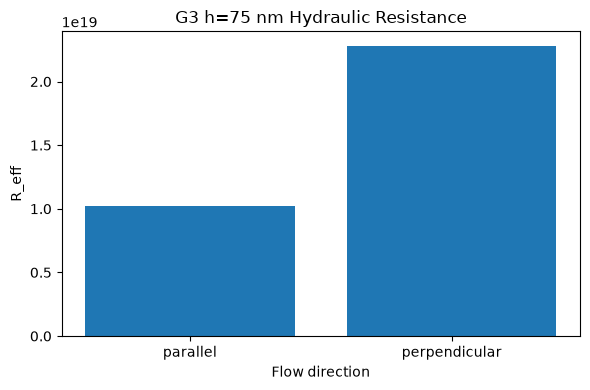

In [4]:
plt.figure(figsize=(6,4))

plt.bar(
    g3_summary["direction"],
    g3_summary["R_eff"]
)

plt.ylabel("R_eff")
plt.xlabel("Flow direction")
plt.title("G3 h=75 nm Hydraulic Resistance")

plt.tight_layout()

plt.show()

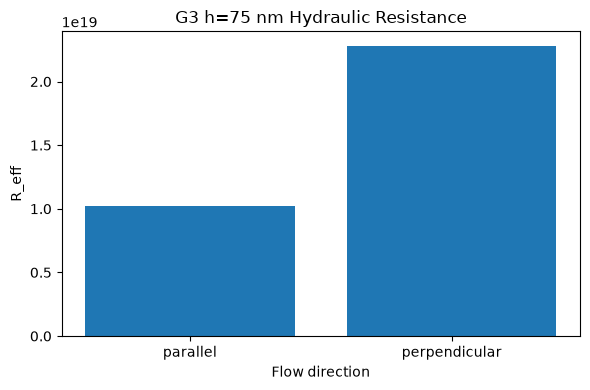

/home/dell/yuanyuanxu/SIM240/figures/G3/G3_h75_R_eff_direction.png


In [5]:
fig_dir = Path.home() / "yuanyuanxu/SIM240/figures/G3"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(6,4))

plt.bar(
    g3_summary["direction"],
    g3_summary["R_eff"]
)

plt.ylabel("R_eff")
plt.xlabel("Flow direction")
plt.title("G3 h=75 nm Hydraulic Resistance")

plt.tight_layout()

plt.savefig(
    fig_dir / "G3_h75_R_eff_direction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(fig_dir / "G3_h75_R_eff_direction.png")

In [ ]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks': PROJECT = PROJECT.parent
RESULTS = PROJECT / 'CASE/04_parameter_study/G3_EX240_height_sweep/results'
ANALYSIS = PROJECT / 'analysis/results'
FIGURES = PROJECT / 'figures/G3'
ANALYSIS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 140, 'savefig.dpi': 600, 'font.size': 11, 'axes.labelsize': 12})

## 1. 自动读取真实 G3 结果

In [ ]:
files = sorted(RESULTS.rglob('result_summary.csv'))
rows = []
for path in files:
    # 支持当前结果直接位于 *_P/*_T，也兼容 *_P/steady/*_T/steady。
    tag = next((p.name for p in path.parents if re.search(r'_([PT])$', p.name)), '')
    m = re.search(r'h(\d+(?:p\d+)?)', str(path), re.I)
    if not tag or not m: continue
    height = float(m.group(1).replace('p', '.'))
    frame = pd.read_csv(path)
    frame['height'] = height
    frame['source_path'] = str(path)
    rows.append(frame)
if not rows: raise FileNotFoundError(f'No G3 result_summary.csv found under {RESULTS}')
data = pd.concat(rows, ignore_index=True)
required = ['Case','direction','dx','tau','force','J','Keff','R_eff','Mach','mass_error']
missing = [c for c in required if c not in data.columns]
if missing: raise ValueError(f'Missing required fields: {missing}')
data = data[['height'] + required + ['source_path']].sort_values(['height','direction']).reset_index(drop=True)
data

In [ ]:
out_csv = ANALYSIS / 'G3_height_summary.csv'
data.to_csv(out_csv, index=False)
print(f'Wrote {out_csv} ({len(data)} rows)')

## 2. 数值稳定性检查

In [ ]:
mach_pass = (data['Mach'] < 0.1).all()
mass_pass = (data['mass_error'].abs() < 1e-10).all()
print(f'Mach max = {data.Mach.max():.6e}; Mach < 0.1: {mach_pass}')
print(f'max |mass_error| = {data.mass_error.abs().max():.6e}; mass gate: {mass_pass}')
print('Numerical validation PASS' if mach_pass and mass_pass else 'Numerical validation FAIL')

## 3. 第一批论文图

In [ ]:
colors = {'parallel':'#2166ac', 'perpendicular':'#b2182b'}
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=600, bbox_inches='tight')
    plt.savefig(FIGURES / f'{name}.pdf', dpi=600, bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(figsize=(6.8,4.4))
for direction, group in data.groupby('direction'):
    group = group.sort_values('height')
    ax.plot(group.height, group.R_eff, 'o-', label=direction, color=colors.get(direction))
ax.set(xlabel='Liquid-film height h (nm)', ylabel='R_eff (Pa s/m³)', title='G3-h directional resistance')
ax.legend(frameon=False); savefig('R_eff_parallel_vs_perpendicular')

In [ ]:
fig, ax = plt.subplots(figsize=(6.8,4.4))
for direction, group in data.groupby('direction'):
    group = group.sort_values('height')
    ax.plot(group.height, group.Keff, 'o-', label=direction, color=colors.get(direction))
ax.set(xlabel='Liquid-film height h (nm)', ylabel='K_eff (m³/(Pa s))', title='G3-h directional mobility')
ax.legend(frameon=False); savefig('Keff_parallel_vs_perpendicular')

In [ ]:
fig, ax1 = plt.subplots(figsize=(6.8,4.4))
for direction, group in data.groupby('direction'):
    ax1.scatter(group.height, group.Mach, label=f'{direction} Mach', color=colors.get(direction), marker='o')
ax1.set(xlabel='Liquid-film height h (nm)', ylabel='Mach')
ax1.axhline(0.1, color='black', ls='--', lw=1, label='Ma=0.1')
ax2 = ax1.twinx()
ax2.scatter(data.height, data.mass_error.abs(), color='#4d9221', marker='x', label='|mass error|')
ax2.set_yscale('log'); ax2.set_ylabel('|mass error|')
ax1.set_title('G3-h numerical stability'); savefig('Mach_mass_error_check')

## 4. LBM 物理分析

In [ ]:
analysis_text = ('## G3-h 物理解释\n\n'
'在相同周期体力下，平行沟槽方向通常具有较小的 R_eff，因为主流沿连续沟槽通道发展，壁面法向速度梯度和横向动量重分配较弱。横向流动必须跨越台阶/沟槽边缘，产生更强的剪切、局部回流和动量耗散，因此 R_eff 通常更高。\n\n'
'随着 h 增大，流体截面和可用剪切长度改变；速度分布由近壁强梯度逐渐过渡到更宽的核心区。Bouzidi 壁面边界通过 link-wise 动量交换施加无滑移条件，壁面附近的非平衡应力直接影响耗散和 K_eff。\n\n'
'上述机制解释必须结合真实 R_eff(h)、速度/压力剖面和耗散输出；不能仅凭单一高度或几何直觉外推。\n')
print(analysis_text)
(ANALYSIS / 'G3_height_physics_discussion.md').write_text(analysis_text, encoding='utf-8')